# Baseline text-classification models

This notebook reads only `combined_text` and `fraudulent` from the processed CSV. It creates a new 80/20 stratified train/test split (`random_state=42`); the existing `split` marker and previously scaled/encoded columns are intentionally ignored. The target is mapped as `f` = legitimate (0) and `t` = fraudulent (1).

A `Pipeline` puts TF-IDF and its classifier together. Each pipeline is fitted only on training text, so the test vocabulary and IDF weights cannot influence training. No SMOTE or other resampling is used.

**Why leakage matters:** if TF-IDF learns vocabulary or inverse-document-frequency weights from test postings, information from the evaluation set has influenced the model. The reported score would no longer be an honest estimate on unseen postings. Likewise, resampling before splitting can copy or synthesize training examples into the test set. Here, split first, fit transforms only on training, and evaluate on the held-out test data. A second stratified split inside the training set selects the best baseline using validation PR-AUC; the test set does not select the model.

**Why accuracy is not enough:** about 95% of the inspected records are legitimate. A classifier that predicts every posting as legitimate could look highly accurate while catching zero fraud. We therefore report fraud-class precision, recall, F1, ROC-AUC, PR-AUC, and confusion matrices in addition to accuracy. PR-AUC (average precision) is especially informative when the positive fraud class is rare.

Loaded 17,645 rows from data\processed\processed_job_postings.csv
Class counts (0=legitimate, 1=fraudulent):


,count
fraudulent,
legitimate (f),16787
fraudulent (t),858


Training rows: 14,116; test rows: 3,529
Fraud class fraction — train: 0.0486; test: 0.0487
Inner fit rows: 11,292; validation rows: 2,824

Training Logistic Regression (balanced)...


                precision    recall  f1-score   support

Legitimate (f)     0.9927    0.9747    0.9836      3357
Fraudulent (t)     0.6352    0.8605    0.7309       172

      accuracy                         0.9691      3529
     macro avg     0.8140    0.9176    0.8572      3529
  weighted avg     0.9753    0.9691    0.9713      3529

Fraud-class ROC-AUC: 0.9840
Fraud-class PR-AUC (average precision): 0.8633

Training Multinomial Naive Bayes...


                precision    recall  f1-score   support

Legitimate (f)     0.9680    0.9991    0.9833      3357
Fraudulent (t)     0.9531    0.3547    0.5169       172

      accuracy                         0.9677      3529
     macro avg     0.9605    0.6769    0.7501      3529
  weighted avg     0.9672    0.9677    0.9606      3529

Fraud-class ROC-AUC: 0.9448
Fraud-class PR-AUC (average precision): 0.6426

Training LinearSVC...


                precision    recall  f1-score   support

Legitimate (f)     0.9876    0.9973    0.9924      3357
Fraudulent (t)     0.9353    0.7558    0.8360       172

      accuracy                         0.9855      3529
     macro avg     0.9614    0.8766    0.9142      3529
  weighted avg     0.9851    0.9855    0.9848      3529

Fraud-class ROC-AUC: 0.9765
Fraud-class PR-AUC (average precision): 0.8879

Model comparison (fraud is the positive class):


,model,validation_pr_auc_for_selection,validation_f1_for_selection,accuracy,precision_fraud,recall_fraud,f1_fraud,roc_auc,pr_auc_average_precision
0,LinearSVC,0.9354,0.8607,0.9855,0.9353,0.7558,0.8360,0.9765,0.8879
1,Logistic Regression (balanced),0.9228,0.8013,0.9691,0.6352,0.8605,0.7309,0.9840,0.8633
2,Multinomial Naive Bayes,0.6734,0.5319,0.9677,0.9531,0.3547,0.5169,0.9448,0.6426


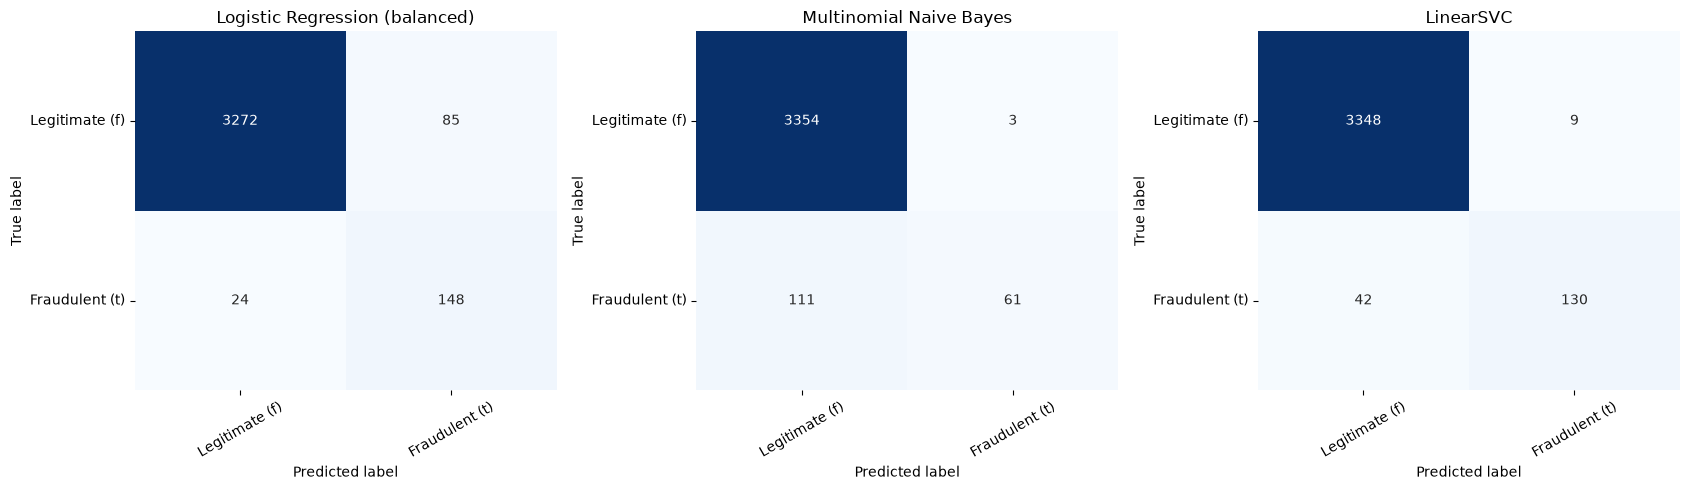


Selected baseline by training-validation PR-AUC, with validation fraud F1 as tie-breaker: LinearSVC
Saved complete TF-IDF + classifier pipeline: models\best_baseline_model.joblib
Saved model metadata: models\best_baseline_model_metadata.json
Saved comparison: report\baseline_model_comparison.csv
Saved classification reports: report\baseline_classification_reports.txt
Saved confusion-matrix plot: report\baseline_confusion_matrices.png
Joblib reload check passed.


In [1]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif PROJECT_DIR.name != "fake-job-detector" and (PROJECT_DIR / "fake-job-detector").is_dir():
    PROJECT_DIR = PROJECT_DIR / "fake-job-detector"

DATA_PATH = PROJECT_DIR / "data" / "processed" / "processed_job_postings.csv"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "report"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Processed dataset not found: {DATA_PATH}")

# Load only the two source columns needed for this text-only baseline.
data = pd.read_csv(DATA_PATH, usecols=["combined_text", "fraudulent"])
data = data.dropna(subset=["fraudulent"]).copy()
data["combined_text"] = data["combined_text"].fillna("").astype(str)
label_map = {"f": 0, "t": 1}
labels = data["fraudulent"].astype(str).str.strip().str.lower()
unexpected_labels = sorted(set(labels.unique()) - set(label_map))
if unexpected_labels:
    raise ValueError(f"Unexpected fraudulent label values: {unexpected_labels}")
X = data["combined_text"]
y = labels.map(label_map).astype("int8")
print(f"Loaded {len(data):,} rows from {DATA_PATH.relative_to(PROJECT_DIR)}")
print("Class counts (0=legitimate, 1=fraudulent):")
display(y.value_counts().sort_index().rename(index={0: "legitimate (f)", 1: "fraudulent (t)"}).rename("count").to_frame())

# Split before fitting any learned text transformation. Existing `split` is not read or reused.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Fraud class fraction — train: {:.4f}; test: {:.4f}".format(y_train.mean(), y_test.mean()))

# A validation partition inside training data selects the saved baseline without using test scores.
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42,
)
print(f"Inner fit rows: {len(X_fit):,}; validation rows: {len(X_validation):,}")

def make_pipeline(classifier):
    """Keep TF-IDF and the estimator together so the fitted transform is saved too."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10_000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
        )),
        ("classifier", classifier),
    ])

models = {
    "Logistic Regression (balanced)": make_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    ),
    "Multinomial Naive Bayes": make_pipeline(MultinomialNB()),
    "LinearSVC": make_pipeline(LinearSVC(random_state=42)),
}

positive_class = 1  # fraudulent (t)
class_order = [0, 1]
target_names = ["Legitimate (f)", "Fraudulent (t)"]
results = []
classification_reports = {}
confusion_matrices = {}
fitted_models = {}

for model_name, pipeline in models.items():
    print(f"\nTraining {model_name}...")
    # Select among candidates using validation data carved from training only.
    validation_pipeline = make_pipeline(pipeline.named_steps["classifier"])
    validation_pipeline.fit(X_fit, y_fit)
    if hasattr(validation_pipeline, "predict_proba"):
        validation_scores = validation_pipeline.predict_proba(X_validation)[:, 1]
    else:
        validation_scores = validation_pipeline.decision_function(X_validation)
    validation_predictions = validation_pipeline.predict(X_validation)
    validation_pr_auc = average_precision_score(y_validation, validation_scores)
    validation_f1 = f1_score(y_validation, validation_predictions, pos_label=positive_class, zero_division=0)

    # Refit a fresh TF-IDF + classifier pipeline on the full training partition for final test evaluation.
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    # ROC-AUC needs a continuous score. All three estimators expose either probabilities
    # or a decision function through the pipeline, so it is available without using labels.
    if hasattr(pipeline, "predict_proba"):
        fraud_scores = pipeline.predict_proba(X_test)[:, 1]
    elif hasattr(pipeline, "decision_function"):
        fraud_scores = pipeline.decision_function(X_test)
    else:
        fraud_scores = None

    metrics = {
        "model": model_name,
        "validation_pr_auc_for_selection": validation_pr_auc,
        "validation_f1_for_selection": validation_f1,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_fraud": precision_score(y_test, predictions, pos_label=positive_class, zero_division=0),
        "recall_fraud": recall_score(y_test, predictions, pos_label=positive_class, zero_division=0),
        "f1_fraud": f1_score(y_test, predictions, pos_label=positive_class, zero_division=0),
        "roc_auc": roc_auc_score(y_test, fraud_scores) if fraud_scores is not None else np.nan,
        "pr_auc_average_precision": average_precision_score(y_test, fraud_scores) if fraud_scores is not None else np.nan,
    }
    results.append(metrics)
    fitted_models[model_name] = pipeline
    classification_reports[model_name] = classification_report(
        y_test,
        predictions,
        labels=class_order,
        target_names=target_names,
        zero_division=0,
        digits=4,
    )
    confusion_matrices[model_name] = confusion_matrix(y_test, predictions, labels=class_order)
    print(classification_reports[model_name])
    print("Fraud-class ROC-AUC:", f"{metrics['roc_auc']:.4f}" if np.isfinite(metrics["roc_auc"]) else "not available")
    print("Fraud-class PR-AUC (average precision):", f"{metrics['pr_auc_average_precision']:.4f}" if np.isfinite(metrics["pr_auc_average_precision"]) else "not available")

comparison = pd.DataFrame(results).sort_values(
    by=["validation_pr_auc_for_selection", "validation_f1_for_selection"], ascending=False
).reset_index(drop=True)
print("\nModel comparison (fraud is the positive class):")
display(comparison.style.format({
    "accuracy": "{:.4f}",
    "precision_fraud": "{:.4f}",
    "recall_fraud": "{:.4f}",
    "f1_fraud": "{:.4f}",
    "roc_auc": "{:.4f}",
    "pr_auc_average_precision": "{:.4f}",
    "validation_pr_auc_for_selection": "{:.4f}",
    "validation_f1_for_selection": "{:.4f}",
}))

# Plot one test-set confusion matrix per classifier with consistent class ordering.
fig, axes = plt.subplots(1, len(confusion_matrices), figsize=(17, 5))
for ax, (model_name, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=target_names,
        yticklabels=target_names,
        ax=ax,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
confusion_plot_path = REPORT_DIR / "baseline_confusion_matrices.png"
fig.savefig(confusion_plot_path, dpi=150, bbox_inches="tight")
plt.show()

# Validation PR-AUC is the primary ranking criterion because fraud is rare;
# validation fraud F1 is the tie-breaker. Test metrics do not choose the saved model.
best_model_name = str(comparison.loc[0, "model"])
best_model = fitted_models[best_model_name]
model_path = MODEL_DIR / "best_baseline_model.joblib"
joblib.dump(best_model, model_path)

comparison_path = REPORT_DIR / "baseline_model_comparison.csv"
comparison.to_csv(comparison_path, index=False)
classification_report_path = REPORT_DIR / "baseline_classification_reports.txt"
classification_report_path.write_text(
    "\n\n".join(f"{name}\n{'=' * len(name)}\n{report}" for name, report in classification_reports.items()),
    encoding="utf-8",
)
metadata_path = MODEL_DIR / "best_baseline_model_metadata.json"
metadata_path.write_text(json.dumps({
    "model_name": best_model_name,
    "positive_label": "t",
    "label_mapping": label_map,
    "selection_criterion": "highest training-validation PR-AUC (average precision), then validation fraud-class F1",
    "metrics": comparison.loc[0].to_dict(),
    "tfidf": {
        "max_features": 10000,
        "ngram_range": [1, 2],
        "min_df": 2,
        "sublinear_tf": True,
    },
}, indent=2, default=float), encoding="utf-8")

print(f"\nSelected baseline by training-validation PR-AUC, with validation fraud F1 as tie-breaker: {best_model_name}")
print(f"Saved complete TF-IDF + classifier pipeline: {model_path.relative_to(PROJECT_DIR)}")
print(f"Saved model metadata: {metadata_path.relative_to(PROJECT_DIR)}")
print(f"Saved comparison: {comparison_path.relative_to(PROJECT_DIR)}")
print(f"Saved classification reports: {classification_report_path.relative_to(PROJECT_DIR)}")
print(f"Saved confusion-matrix plot: {confusion_plot_path.relative_to(PROJECT_DIR)}")

# Reload once to verify that the serialized full pipeline can make predictions.
reloaded_pipeline = joblib.load(model_path)
assert len(reloaded_pipeline.predict(X_test.iloc[:5])) == min(5, len(X_test))
print("Joblib reload check passed.")


## Interpretation and leakage check

Use the comparison table and classification reports to see how many fraudulent jobs were caught and how many legitimate jobs were incorrectly flagged. High recall means fewer scams are missed; higher precision means fewer legitimate jobs are mislabeled. The confusion-matrix rows are true classes and columns are predicted classes, ordered legitimate then fraudulent.

The saved artifact is a complete scikit-learn pipeline, including its fitted TF-IDF vocabulary/IDF values and classifier. To assess a future model fairly, any model selection or threshold tuning must use training-only validation; do not repeatedly tune against this held-out test set.